# Facebook's Prophet Library

## Importing the data

👇 Go on [trends.google.com](https://trends.google.com/trends/?geo=US) and retrieve the dataset representing the interest over time of the keyword `data science` since 2004 in the US. Once you get the dataset, import the data and display the first few rows

In [1]:
import sys

print("Version :", sys.version)
print("Environnement :", sys.executable)

Version : 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Environnement : c:\Users\jacqu\OneDrive\Desktop\M2IA\sarimax\jour_3\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# Chemin du fichier CSV
fichier = Path("data_science_google_trends (1).csv")

# Vérifier que le fichier existe
if not fichier.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {fichier.resolve()}"
    )

# Importer le jeu de données
df_raw = pd.read_csv(fichier)

print("Importation réussie !")
print("Dimensions :", df_raw.shape)
print("Colonnes :", df_raw.columns.tolist())

display(df_raw.head())

Importation réussie !
Dimensions : (200, 2)
Colonnes : ['Month', 'data science: (United States)']


,Month,data science: (United States)
0,2004-01,17
1,2004-02,13
2,2004-03,11
3,2004-04,6
4,2004-05,6


## Display the data

👇Visualize the data by displaying the first few rows of the dataframe

In [3]:
# Aperçu des données
display(df_raw.head(10))

# Dernières observations
display(df_raw.tail(10))

# Dimensions
print("Nombre de lignes :", df_raw.shape[0])
print("Nombre de colonnes :", df_raw.shape[1])

# Types de variables
print("\nTypes des variables :")
print(df_raw.dtypes)

# Valeurs manquantes
print("\nValeurs manquantes :")
print(df_raw.isna().sum())

# Statistiques descriptives
display(df_raw.describe(include="all"))

,Month,data science: (United States)
0,2004-01,17
1,2004-02,13
2,2004-03,11
3,2004-04,6
4,2004-05,6
5,2004-06,10
6,2004-07,11
7,2004-08,7
8,2004-09,12
9,2004-10,10


,Month,data science: (United States)
190,2019-11,85
191,2019-12,74
192,2020-01,90
193,2020-02,93
194,2020-03,76
195,2020-04,82
196,2020-05,80
197,2020-06,78
198,2020-07,77
199,2020-08,62


Nombre de lignes : 200
Nombre de colonnes : 2

Types des variables :
Month                              str
data science: (United States)    int64
dtype: object

Valeurs manquantes :
Month                            0
data science: (United States)    0
dtype: int64


,Month,data science: (United States)
count,200,200.000000
unique,200,NaN
top,2004-01,NaN
freq,1,NaN
mean,NaN,27.700000
std,NaN,27.246502
min,NaN,4.000000
25%,NaN,8.000000
50%,NaN,11.000000
75%,NaN,43.250000


## Data Preprocessing

Facebook'Prophet library requires the data to be in a specific format. 

👇 Format the dataset as per Facebook Prophet's requirements.
Remember the dataframe should have a `ds` and `y` columns

In [4]:
# Identifier les deux colonnes
col_date = df_raw.columns[0]
col_valeur = df_raw.columns[1]

# Construire le DataFrame Prophet
df = pd.DataFrame()

# Conversion des dates
df["ds"] = pd.to_datetime(
    df_raw[col_date].astype(str).str.strip(),
    format="%Y-%m",
    errors="coerce"
)

# Conversion des valeurs en numérique
valeurs = df_raw[col_valeur].astype(str).str.strip()

# Google Trends peut parfois indiquer "<1"
valeurs = valeurs.replace("<1", "0.5")

df["y"] = pd.to_numeric(
    valeurs,
    errors="coerce"
)

# Diagnostic avant nettoyage
print("Dates invalides :", df["ds"].isna().sum())
print("Valeurs invalides :", df["y"].isna().sum())
print("Dates dupliquées :", df["ds"].duplicated().sum())

# Nettoyage
df = (
    df.dropna(subset=["ds", "y"])
      .drop_duplicates(subset="ds")
      .sort_values("ds")
      .reset_index(drop=True)
)

if df.empty:
    raise ValueError("Aucune observation valide après nettoyage.")

# Vérifier les mois éventuellement absents
mois_attendus = pd.date_range(
    start=df["ds"].min(),
    end=df["ds"].max(),
    freq="MS"
)

mois_manquants = mois_attendus.difference(df["ds"])

print("\nDonnées préparées pour Prophet")
print("Observations :", len(df))
print("Début :", df["ds"].min().date())
print("Fin :", df["ds"].max().date())
print("Mois absents :", len(mois_manquants))

display(df.head())

Dates invalides : 0
Valeurs invalides : 0
Dates dupliquées : 0

Données préparées pour Prophet
Observations : 200
Début : 2004-01-01
Fin : 2020-08-01
Mois absents : 0


,ds,y
0,2004-01-01,17
1,2004-02-01,13
2,2004-03-01,11
3,2004-04-01,6
4,2004-05-01,6


## Plotting the data

👇 Plot the data

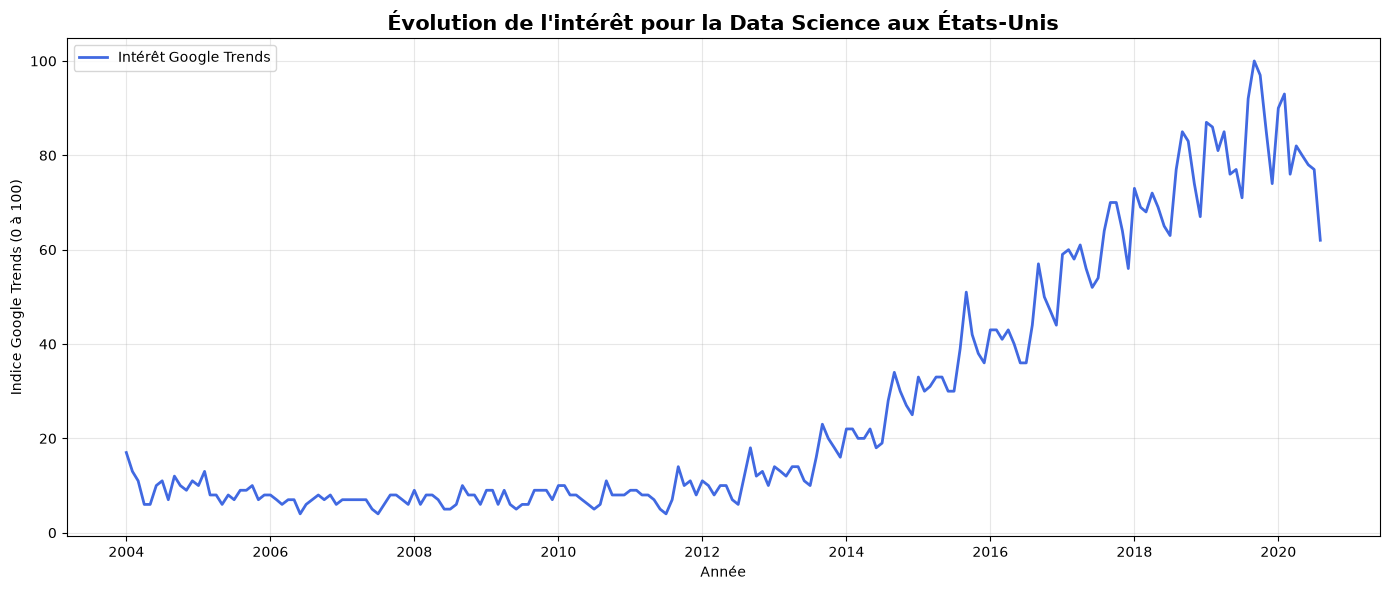

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["ds"],
    df["y"],
    color="royalblue",
    linewidth=2,
    label="Intérêt Google Trends"
)

plt.title(
    "Évolution de l'intérêt pour la Data Science aux États-Unis",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Année")
plt.ylabel("Indice Google Trends (0 à 100)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

La série présente une tendance de long terme nettement croissante, mais cette croissance n'est pas linéaire sur l'ensemble de la période.

Elle montre également des variations de plus en plus importantes lorsque l'indice augmente.

## Fitting the data

👇 Fit the data using Facebook's Prophet library. Make sure to use a train/test split

In [6]:
# Derniers 24 mois pour le test
n_test = 24

train = df.iloc[:-n_test].copy()
test = df.iloc[-n_test:].copy()

print("Taille du train :", len(train))
print("Taille du test :", len(test))

print("\nPériode d'entraînement :")
print(train["ds"].min(), "->", train["ds"].max())

print("\nPériode de test :")
print(test["ds"].min(), "->", test["ds"].max())

Taille du train : 176
Taille du test : 24

Période d'entraînement :
2004-01-01 00:00:00 -> 2018-08-01 00:00:00

Période de test :
2018-09-01 00:00:00 -> 2020-08-01 00:00:00


Le jeu de données contient 200 observations mensuelles, réparties chronologiquement entre un ensemble d'entraînement de 176 observations et un ensemble de test de 24 observations.

In [6]:
%pip install --upgrade prophet cmdstanpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sys
import prophet
import cmdstanpy

print("Python :", sys.version)
print("Prophet :", prophet.__version__)
print("CmdStanPy :", cmdstanpy.__version__)

Importing plotly failed. Interactive plots will not work.


Python : 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Prophet : 1.5.0
CmdStanPy : 1.3.2


c:\Users\jacqu\OneDrive\Desktop\M2IA\sarimax\jour_3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
from prophet import Prophet

model_train = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95,
    seasonality_mode="additive"
)

# Entraîner le modèle
model_train.fit(train)

print("Entraînement terminé avec succès !")

10:31:38 - cmdstanpy - INFO - Chain [1] start processing
10:31:48 - cmdstanpy - INFO - Chain [1] done processing


Entraînement terminé avec succès !


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Prédire les dates du test
pred_test = model_train.predict(test[["ds"]])

# Comparaison avec les données réelles
comparaison_test = test.merge(
    pred_test[
        ["ds", "yhat", "yhat_lower", "yhat_upper"]
    ],
    on="ds"
)

# Métriques
mae = mean_absolute_error(
    comparaison_test["y"],
    comparaison_test["yhat"]
)

rmse = np.sqrt(
    mean_squared_error(
        comparaison_test["y"],
        comparaison_test["yhat"]
    )
)

# MAPE : éviter la division par zéro
valides = comparaison_test["y"] != 0

mape = (
    np.mean(
        np.abs(
            (
                comparaison_test.loc[valides, "y"]
                - comparaison_test.loc[valides, "yhat"]
            )
            / comparaison_test.loc[valides, "y"]
        )
    ) * 100
    if valides.any()
    else np.nan
)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f} %")

display(comparaison_test.head())

MAE  : 8.29
RMSE : 10.71
MAPE : 10.78 %


,ds,y,yhat,yhat_lower,yhat_upper
0,2018-09-01,85,78.308034,73.822670,82.944740
1,2018-10-01,83,76.045460,71.776986,80.379160
2,2018-11-01,74,75.352365,70.406742,79.937555
3,2018-12-01,67,74.126988,69.325784,79.002461
4,2019-01-01,87,80.062144,75.210187,84.668213


Analyse de la MAE : 8,29

La MAE (Mean Absolute Error) représente l'erreur absolue moyenne entre les valeurs observées et les prévisions.

Avec une MAE de 8,29 le modèle se trompe en moyenne d'environ 8,3 points d'indice Google Trends sur les deux années de test.

Cette valeur indique que Prophet parvient à reproduire une partie de l'évolution générale, mais conserve des écarts non négligeables avec les observations réelles.

Analyse de la RMSE : 10,71

La RMSE (Root Mean Squared Error) pénalise davantage les erreurs importantes.

Sa valeur de 10,71 est supérieure à la MAE de 8,29. Cela suggère que certaines observations présentent des erreurs particulièrement élevées, qui augmentent l'erreur quadratique moyenne.

Ce résultat est cohérent avec les fluctuations marquées observées sur la période 2018–2020, notamment la baisse de l'indice à la fin de la série.

Analyse de la MAPE : 10,78 %

La MAPE (Mean Absolute Percentage Error) mesure la moyenne des erreurs relatives absolues.

Une MAPE de 10,78 % signifie que les prévisions s'écartent en moyenne d'environ 10,8 % des valeurs réelles, en valeur relative.

Ce niveau d'erreur peut être considéré comme exploitable pour une première estimation de la tendance, sans être suffisant pour qualifier les prévisions de très précises.

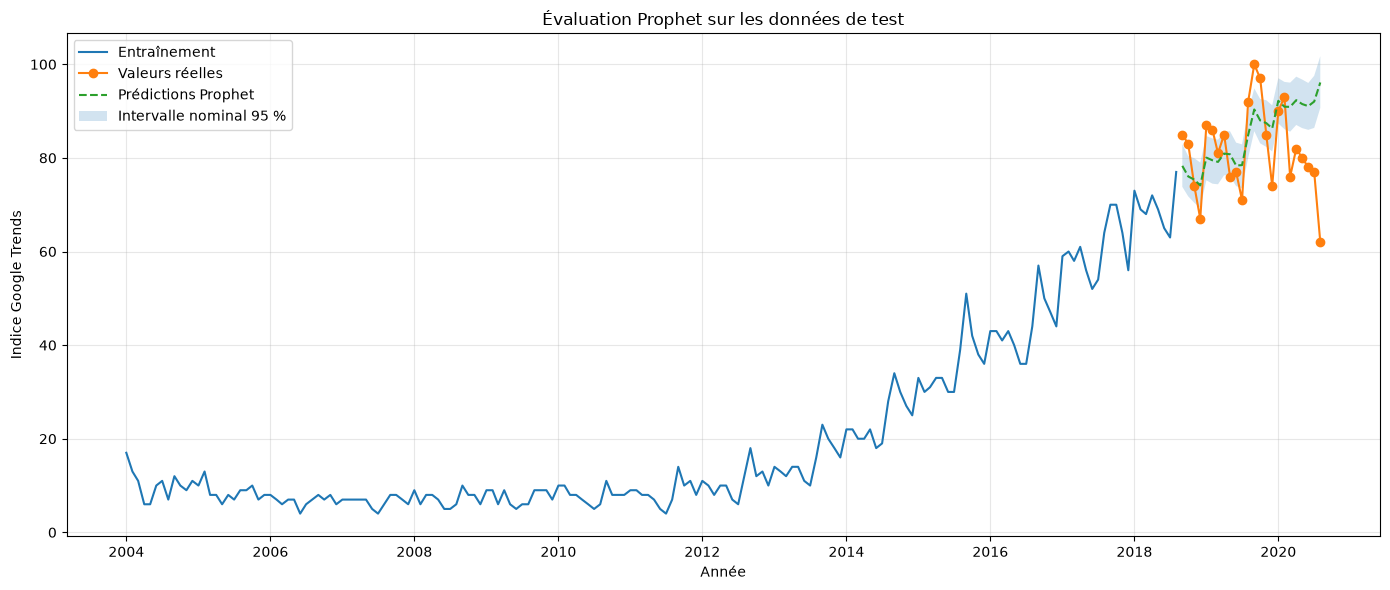

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    train["ds"],
    train["y"],
    label="Entraînement"
)

plt.plot(
    test["ds"],
    test["y"],
    label="Valeurs réelles",
    marker="o"
)

plt.plot(
    comparaison_test["ds"],
    comparaison_test["yhat"],
    label="Prédictions Prophet",
    linestyle="--"
)

plt.fill_between(
    comparaison_test["ds"],
    comparaison_test["yhat_lower"],
    comparaison_test["yhat_upper"],
    alpha=0.2,
    label="Intervalle nominal 95 %"
)

plt.title("Évaluation Prophet sur les données de test")
plt.xlabel("Année")
plt.ylabel("Indice Google Trends")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La courbe verte des prévisions suit globalement la progression observée, ce qui montre que le modèle a correctement identifié la dynamique de croissance historique.

Le modèle capture convenablement la tendance générale de croissance, mais sa capacité à anticiper les changements de régime reste limitée. Ses prévisions sont particulièrement fragiles lors des périodes de forte volatilité.

## Make future predictions

👇Before predicting future values with Facebook's Prophet library, you first need to create a placeholder dataframe that will eventually hold the predictions. Once you create the dataframe, try to predict 2 years in the future.

You can create the predictions' dataframe using `make_future_dataframe()`

In [11]:
# Nouveau modèle sur toutes les données
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

model.fit(df)

# Créer 24 mois supplémentaires
future = model.make_future_dataframe(
    periods=24,
    freq="MS"
)

# Effectuer les prédictions
forecast = model.predict(future)

# Afficher les 24 derniers mois prévus
display(
    forecast[
        ["ds", "yhat", "yhat_lower", "yhat_upper"]
    ].tail(24)
)

10:33:37 - cmdstanpy - INFO - Chain [1] start processing
10:33:37 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
200,2020-09-01,99.013801,91.430438,106.673762
201,2020-10-01,96.439414,88.455123,104.271147
202,2020-11-01,95.307007,87.559167,102.978919
203,2020-12-01,93.851528,86.385529,101.558682
204,2021-01-01,99.441632,91.237817,107.271537
205,2021-02-01,100.232728,92.317032,107.646570
206,2021-03-01,97.421651,90.230835,105.122462
207,2021-04-01,99.473553,91.787838,107.023424
208,2021-05-01,98.571476,91.055888,106.825355
209,2021-06-01,97.452602,89.484098,104.861541


En septembre 2020, le modèle prévoit un indice d'environ 99,01. À l'horizon d'août 2022, cette prévision atteint environ 114,05.

Plusieurs prévisions dépassent 100, alors que l'indice Google Trends historique est normalisé sur une échelle de 0 à 100.

Cela s'explique par le fait que Prophet, dans sa configuration actuelle, ne connaît pas cette contrainte. Il prolonge mathématiquement la tendance observée.

Les résultats suggèrent que le modèle anticipe une poursuite de l'intérêt croissant pour la data science. Cependant, les dépassements de la limite de 100 et l'absence d'informations postérieures à août 2020 limitent fortement l'interprétation quantitative des prévisions.

## Plotting the forecast

👇 It's time to visualize our forecast. Make use of the handy [`model.plot(forecast)`](https://facebook.github.io/prophet/docs/quick_start.html)

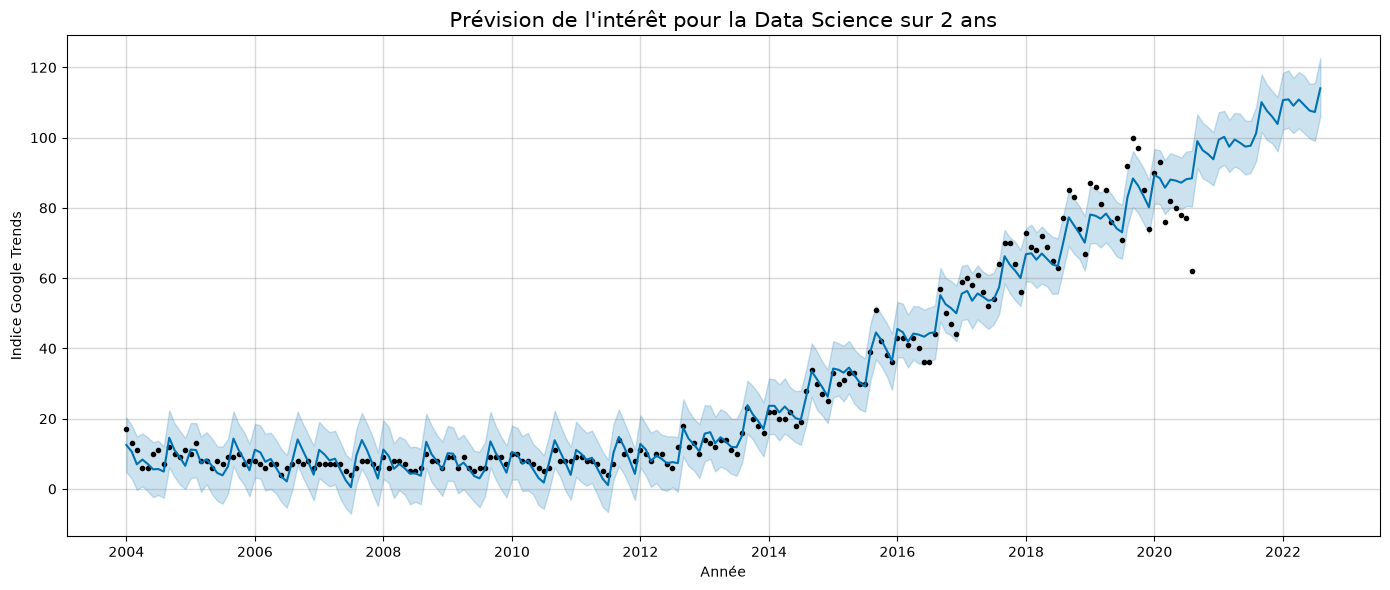

In [12]:
fig = model.plot(
    forecast,
    figsize=(14, 6)
)

plt.title(
    "Prévision de l'intérêt pour la Data Science sur 2 ans",
    fontsize=15
)

plt.xlabel("Année")
plt.ylabel("Indice Google Trends")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

👉 From 2004 to 2018 we can see the train data and the forecasted data from 2018 to 2020.

We can also notice a shaded region behind the plot which represents the 95% uncertainty interval.

The black dots represent the original data

## Time Series' trend and seasonality

👇 Plot the trend and yearly seasonality of the time series. This can be done using the `plot_components()` function from Facebook's Prophet Library

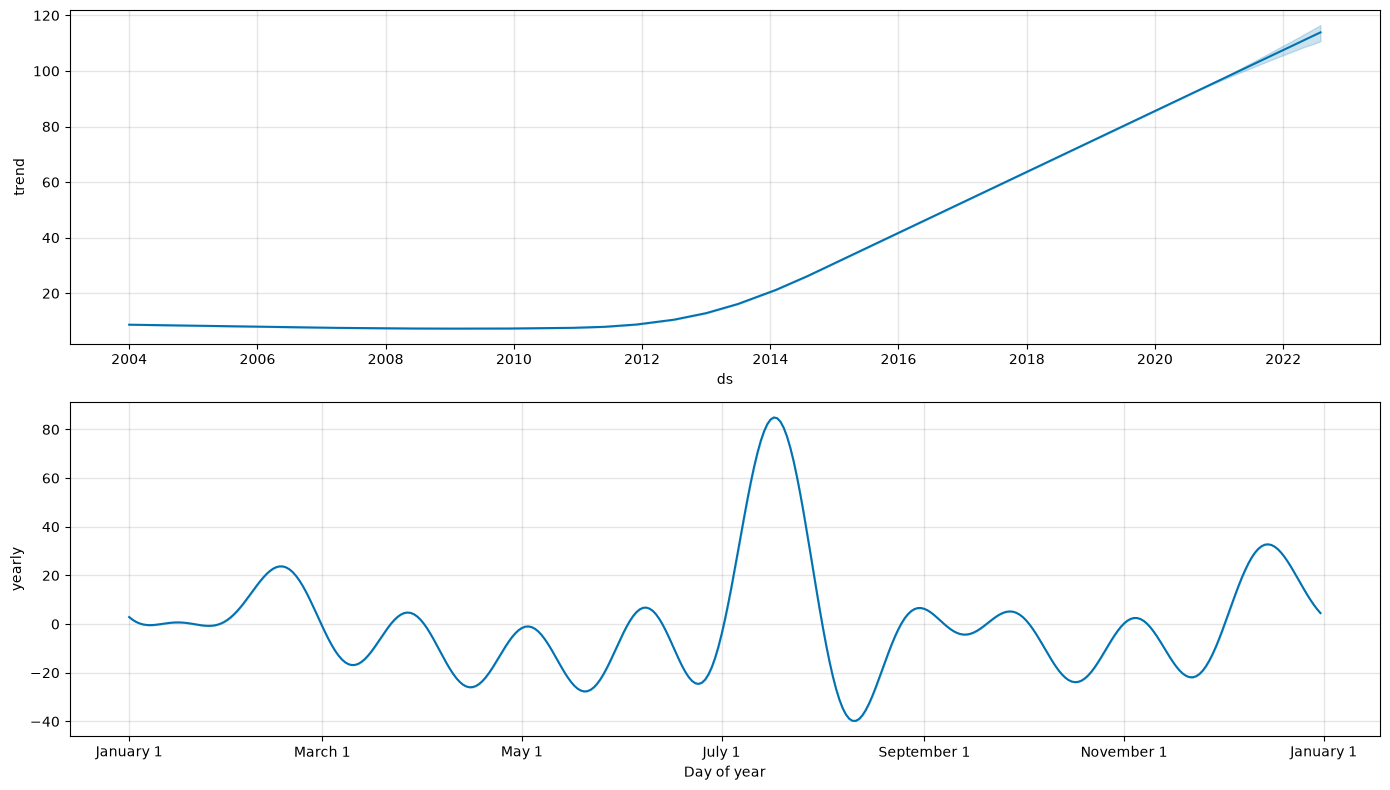

In [13]:
fig = model.plot_components(
    forecast,
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

Le premier graphique présente la tendance estimée par Prophet indépendamment des fluctuations saisonnières.

Entre 2004 et 2011, la tendance apparaît relativement stable, avec un indice situé principalement autour de 7 à 9 points.

À partir de 2012, une augmentation progressive apparaît. Cette croissance s'accélère particulièrement entre 2014 et 2020, période durant laquelle la tendance estimée augmente fortement.

Le modèle prolonge ensuite cette croissance jusqu'en 2022, avec une tendance dépassant 110 points.

Cette représentation confirme le changement de dynamique déjà identifié lors de l'analyse exploratoire : la série passe d'une longue phase de stabilité à une phase de forte croissance.

Le deuxième graphique représente l'effet saisonnier estimé pour les différents moments de l'année.

On observe plusieurs pics et creux, notamment un pic très marqué autour de juillet, avec un effet estimé proche de +85 points, suivi d'une chute importante pouvant atteindre environ -40 points au début du mois d'août.

Le profil saisonnier obtenu est donc susceptible de refléter un phénomène de surajustement plutôt qu'une véritable saisonnalité annuelle.

## Evaluating the model with cross-validation!

👇 Using `cross_validation` and `performance_metrics` from [fbprophet.diagnostics](https://facebook.github.io/prophet/docs/diagnostics.html), evaluate the performance of your model
<img src='https://facebook.github.io/prophet/static/diagnostics_files/diagnostics_3_0.png'>

More precisely, create a Time Series K-fold CV with
- train sets of size 5 years
- horizon val sizes of 1 years
- shifting each fold by 180 days

In [14]:
from prophet.diagnostics import cross_validation

# Validation croisée temporelle
df_cv = cross_validation(
    model,
    initial="1825 days",
    period="180 days",
    horizon="365 days"
)

print("Validation croisée terminée !")
print("Nombre de prédictions :", len(df_cv))

display(df_cv.head())

  0%|          | 0/22 [00:00<?, ?it/s]10:33:48 - cmdstanpy - INFO - Chain [1] start processing
10:33:48 - cmdstanpy - INFO - Chain [1] done processing
  5%|▍         | 1/22 [00:00<00:07,  2.96it/s]10:33:48 - cmdstanpy - INFO - Chain [1] start processing
10:33:49 - cmdstanpy - INFO - Chain [1] done processing
  9%|▉         | 2/22 [00:00<00:06,  3.07it/s]10:33:49 - cmdstanpy - INFO - Chain [1] start processing
10:33:49 - cmdstanpy - INFO - Chain [1] done processing
 14%|█▎        | 3/22 [00:01<00:06,  2.87it/s]10:33:49 - cmdstanpy - INFO - Chain [1] start processing
10:33:49 - cmdstanpy - INFO - Chain [1] done processing
 18%|█▊        | 4/22 [00:01<00:06,  2.96it/s]10:33:49 - cmdstanpy - INFO - Chain [1] start processing
10:33:50 - cmdstanpy - INFO - Chain [1] done processing
 23%|██▎       | 5/22 [00:01<00:05,  3.12it/s]10:33:50 - cmdstanpy - INFO - Chain [1] start processing
10:33:50 - cmdstanpy - INFO - Chain [1] done processing
 27%|██▋       | 6/22 [00:01<00:05,  3.06it/s]10:33:50

Validation croisée terminée !
Nombre de prédictions : 264


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2009-04-01,5.593584,3.075532,7.976515,9,2009-03-27
1,2009-05-01,5.002490,2.655507,7.426750,6,2009-03-27
2,2009-06-01,5.096166,2.676105,7.463485,5,2009-03-27
3,2009-07-01,5.344689,2.881350,7.735881,6,2009-03-27
4,2009-08-01,5.562377,3.368963,8.086101,6,2009-03-27


Le protocole repose sur une période d'entraînement initiale d'environ cinq ans (1 825 jours), un horizon de prévision de 365 jours et un décalage de 180 jours entre deux dates de validation successives.

Cette méthode permet de simuler plusieurs situations dans lesquelles le modèle doit prédire les observations futures à partir des seules données disponibles auparavant.

Contrairement à une validation croisée classique utilisant des partitions aléatoires, les observations restent ordonnées chronologiquement.

L'entraînement repose ici sur des fenêtres historiques qui s'agrandissent progressivement, et non sur des fenêtres fixes de cinq ans.

La validation croisée a généré 264 prédictions, correspondant à 22 dates de coupure temporelle et 12 observations mensuelles évaluées par période.

In [15]:
try:
    from prophet.diagnostics import performance_metrics
except ImportError:
    from prophet.metrics import performance_metrics

# Calcul des performances
df_perf = performance_metrics(df_cv)

# Afficher les résultats
display(
    df_perf[
        ["horizon", "mae", "rmse", "mape", "coverage"]
    ].head(10)
)

# Résumé global
resume_cv = performance_metrics(
    df_cv,
    rolling_window=1
)

display(
    resume_cv[
        ["mae", "rmse", "mape", "coverage"]
    ]
)

,horizon,mae,rmse,mape,coverage
0,39 days,3.746210,4.855245,0.143115,0.461538
1,40 days,3.612087,4.802366,0.134271,0.500000
2,42 days,3.519803,4.755029,0.125700,0.538462
3,44 days,3.486298,4.749748,0.122144,0.538462
4,45 days,3.085295,4.017278,0.116251,0.576923
5,47 days,3.393479,4.329634,0.121235,0.538462
6,49 days,3.460453,4.356732,0.126161,0.500000
7,50 days,3.614693,4.505533,0.127293,0.480769
8,51 days,3.607747,4.434454,0.139199,0.461538
9,52 days,3.517018,4.326527,0.137115,0.500000


,mae,rmse,mape,coverage
0,4.535009,6.086781,0.158455,0.465909


Sur l'ensemble des prévisions évaluées par validation croisée, le modèle présente une erreur absolue moyenne de 4,54 points d'indice.

Cette valeur indique que les prévisions restent relativement proches des observations réelles en valeur absolue, lorsqu'on considère les différentes périodes historiques.

La RMSE de 6,09 est supérieure à la MAE, ce qui confirme la présence d'erreurs ponctuellement plus importantes.

Ces résultats montrent que les performances ne sont pas parfaitement homogènes sur toute la période historique.

La MAPE moyenne est de 15,85 %, ce qui signifie que les prévisions présentent un écart relatif moyen d'environ 15,9 % par rapport aux observations réelles.

Cet indicateur nuance les résultats obtenus avec la MAE et la RMSE : le modèle peut présenter des erreurs absolues relativement faibles, mais celles-ci deviennent importantes en pourcentage lorsque l'indice réel est lui-même faible.

C'est particulièrement pertinent pour les premières années, lorsque l'intérêt Google Trends évolue fréquemment autour de 5 à 15 points.

Interprétation du Coverage : 46,59 %

La couverture mesure la proportion des observations réellement comprises dans les intervalles de prévision estimés.

Alors que le modèle utilise un intervalle nominal à 95 %, seulement 46,59 % des observations évaluées sont effectivement comprises dans ces intervalles.

Ce résultat indique une sous-estimation importante de l'incertitude : les intervalles produits par le modèle sont trop étroits ou mal positionnés par rapport à la variabilité réellement observée.

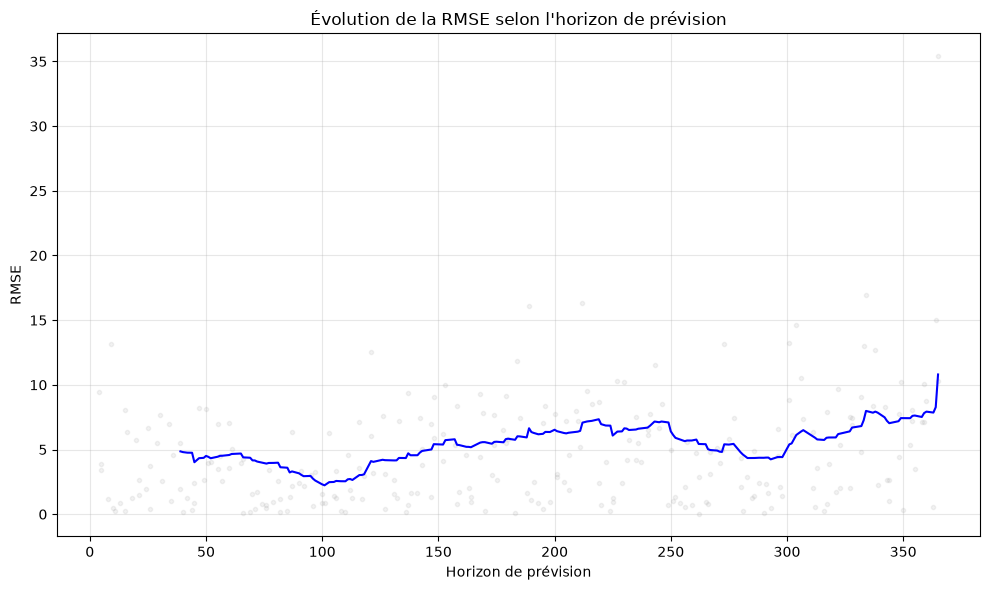

In [16]:
from prophet.plot import plot_cross_validation_metric

fig = plot_cross_validation_metric(
    df_cv,
    metric="rmse"
)

plt.title(
    "Évolution de la RMSE selon l'horizon de prévision"
)

plt.xlabel("Horizon de prévision")
plt.ylabel("RMSE")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Le graphique représente l'évolution de l'erreur quadratique moyenne en fonction de la distance entre la date de prévision et la date de coupure utilisée pour entraîner le modèle.

Les points gris représentent les erreurs obtenues pour les différentes prédictions individuelles, tandis que la courbe bleue présente l'évolution agrégée de la RMSE selon l'horizon.

Pour les horizons courts, autour de 40 à 60 jours, la RMSE se situe approximativement entre 4 et 5 points.

L'erreur varie ensuite de manière non linéaire. Elle diminue temporairement autour de 100 jours, puis augmente progressivement sur plusieurs portions du graphique.

Sur les horizons les plus longs, elle se situe fréquemment autour de 7 à 8 points, avant d'augmenter plus fortement à l'approche de 365 jours, où elle dépasse 10 points.

La présence de plusieurs observations isolées présentant des erreurs importantes, parfois supérieures à 15 ou 30 points, indique que certaines prévisions sont particulièrement éloignées des valeurs réelles.

In [17]:
from pathlib import Path

# Créer un dossier de sortie
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Exporter les prévisions
forecast[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].to_csv(
    output_dir / "prophet_previsions.csv",
    index=False
)

# Exporter les performances
df_perf.to_csv(
    output_dir / "prophet_metriques_cv.csv",
    index=False
)

# Exporter la comparaison avec le test
comparaison_test.to_csv(
    output_dir / "prophet_test_comparaison.csv",
    index=False
)

print("Tous les fichiers ont été sauvegardés !")

Tous les fichiers ont été sauvegardés !


⚠️ Don't forget to push the challenge to GitHub (if you have an account )once you're done 😄 and send me the file